In [1]:
# Run this ONCE. It writes the data file next to this notebook.
# Real MOPS data: 7-ELEVEN (2912) and FamilyMart (5903), FY2021-FY2025, NT$ thousand.
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

DATA = """company,year,revenue,cogs,gross_profit,operating_expenses,operating_income,finance_costs,non_operating,pretax_income,income_tax,net_income,cash,receivables,inventory,total_current_assets,right_of_use_assets,total_assets,accounts_payable,accounts_payable_related,short_term_borrowings,lease_liabilities_current,total_current_liabilities,long_term_borrowings,lease_liabilities_noncurrent,total_liabilities,total_equity,total_assets_begin,total_equity_begin,inventory_begin,receivables_begin,accounts_payable_begin,accounts_payable_related_begin
2912,FY2021,262735464,174611824,88123640,77453709,10669931,1214428,1401764,12071695,2053159,10018536,45648486,6484621,18439779,79411842,77317014,214504035,23255735,3046035,5095702,14119100,88598018,963418,66918530,171712543,42791492,209493934,44977699,16636055,6215272,22255284,2801552
2912,FY2022,290434137,192579613,97854524,85514506,12340018,1179816,1729963,14069981,3000058,11069923,48540378,6701248,21670453,85087134,85032424,233209800,25396205,3446778,9250522,13955348,97709081,492617,74877664,187561717,45648083,214504035,42791492,18439779,6484621,23255735,3046035
2912,FY2023,317041854,208869628,108172226,94421750,13750476,1379574,2606883,16357359,3696228,12661131,48929582,7340609,23427376,95046407,88197513,257352472,28401121,3670965,9798343,14599887,108883539,6351627,78066236,209505072,47847400,233209800,45648083,21670453,6701248,25396205,3446778
2912,FY2024,337932397,222504647,115427750,101455015,13972735,1620707,3388852,17361587,3620148,13741439,51267712,7577551,23631957,92767824,91426317,269782277,30180289,3951265,6492532,15340071,107771441,14729512,80316561,217761619,52020658,257352472,47847400,23427376,7340609,28401121,3670965
2912,FY2025,350734591,230193275,120541316,106611292,13930024,2080499,3015017,16945041,3610759,13334282,50182134,7617155,26709097,94547458,101115343,292630628,26667075,4325672,12133459,16162821,120598789,15164601,88713790,239704065,52926563,269782277,52020658,23631957,7577551,30180289,3951265
5903,FY2021,83659512,53449527,30209985,28543464,1666521,240789,114693,1781214,371465,1409749,7239830,1447163,6240740,17134275,27863199,67606285,9621803,896219,3443375,5516397,33982370,45454,23565007,60610449,6995836,61474390,6986799,5434055,1132601,9176446,764685
5903,FY2022,90742893,57830899,32911994,31229668,1682326,297082,491778,2174104,278085,1896019,6812614,1562662,6777647,18550302,29098043,73588505,10979515,920525,2690537,5673660,37053473,890555,24854170,65713728,7874777,67606285,6995836,6240740,1447163,9621803,896219
5903,FY2023,99610211,63253312,36356899,34344984,2011915,324621,-52896,1959019,270074,1688945,6478343,1676470,7238216,18843929,29145265,75454656,11401452,1205250,2359550,5851854,37913123,915397,24713605,66840180,8614476,73588505,7874777,6777647,1562662,10979515,920525
5903,FY2024,105104290,66715542,38388748,36330453,2058295,339425,2773081,4831376,895070,3936306,8067692,1517129,6398028,19460670,29610524,79729638,12400619,1324119,1938260,6091644,39062310,959398,24964416,68192740,11536898,75454656,8614476,7238216,1676470,11401452,1205250
5903,FY2025,110042154,69994621,40047533,38193033,1854500,385811,423046,2277546,483251,1794295,7157594,1695564,7022840,19408915,29773176,81318202,13509637,1276353,1967590,6330215,40401932,2027778,24955934,70681871,10636331,79729638,11536898,6398028,1517129,12400619,1324119
"""
open("fin_both.csv", "w", encoding="utf-8").write(DATA)
print("Data file ready: fin_both.csv")

Data file ready: fin_both.csv


## The data / 資料說明
One table, **one row per company and year** (10 rows). `company` is a number: `2912` or `5903`, not text.
All amounts are **NT$ thousand**. 一列是一家公司的一個年度；金額單位是新台幣千元。

| Group | Columns |
|---|---|
| Keys | `company`, `year` |
| Income statement | `revenue`, `cogs`, `gross_profit`, `operating_expenses`, `operating_income`, `finance_costs`, `non_operating`, `pretax_income`, `income_tax`, `net_income` |
| Assets | `cash`, `receivables`, `inventory`, `total_current_assets`, `right_of_use_assets`, `total_assets` |
| Liabilities and equity | `accounts_payable`, `accounts_payable_related`, `short_term_borrowings`, `lease_liabilities_current`, `total_current_liabilities`, `long_term_borrowings`, `lease_liabilities_noncurrent`, `total_liabilities`, `total_equity` |
| Opening balances | `total_assets_begin`, `total_equity_begin`, `inventory_begin`, `receivables_begin`, `accounts_payable_begin`, `accounts_payable_related_begin` |

- `non_operating` is the net total of non-operating income and expenses; `finance_costs` is one of the lines inside it.
- `right_of_use_assets` is the leased space a company has the right to use — mostly store leases — carried on the
  balance sheet as an asset. 使用權資產：租來的店面等使用權，認列在資產裡。
- `accounts_payable_related` is what the company owes to related parties. It is **not** included in `accounts_payable`.
- A `_begin` column is the balance at the **start** of that year, which is the previous year's closing balance.
  An average balance is (begin + end) / 2. `_begin` 是該年度的期初餘額，也就是上一年的期末餘額。
- FamilyMart restated its FY2022 total assets and total liabilities in its FY2023 report. This table keeps the
  figures as first reported, so every `_begin` value equals the previous row's closing value.
  全家 FY2022 的資產與負債總額在次年報表重編過，本表一律用原始申報數。

# 1. Data Preprocessing & Validation

In [2]:
# Load the table and look at it before using it.
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("fin_both.csv")
print("A1 shape:", "df.shape")     # <-- the attribute that reports a table's size as (rows, columns)
df.info()

A1 shape: df.shape
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   company                         10 non-null     int64 
 1   year                            10 non-null     object
 2   revenue                         10 non-null     int64 
 3   cogs                            10 non-null     int64 
 4   gross_profit                    10 non-null     int64 
 5   operating_expenses              10 non-null     int64 
 6   operating_income                10 non-null     int64 
 7   finance_costs                   10 non-null     int64 
 8   non_operating                   10 non-null     int64 
 9   pretax_income                   10 non-null     int64 
 10  income_tax                      10 non-null     int64 
 11  net_income                      10 non-null     int64 
 12  cash                            10

In [3]:
# Two checks on every row: does the balance sheet balance, and does gross profit add up?
# Step 1: each check is a NEW COLUMN of True / False. Give df a column name it does not have yet,
# and compare two numbers with == . Comparing whole columns gives you one True or False per row.
df["balanced"] = (df["total_assets"] == df["total_liabilities"] + df["total_equity"])    # <-- True where total assets equal total liabilities plus total equity
df["gp_ok"] = (df["gross_profit"] == df["revenue"] - df["cogs"])                         # <-- True where gross profit equals revenue minus cost of goods sold
print(df[["company", "year", "balanced", "gp_ok"]])

# Step 2: write two for loops, each one walking down a column of your True / False values.
for b in df["balanced"]:
    print("balanced:", b)

for g in df["gp_ok"]:
    print("gp_ok:", g)


   company    year  balanced  gp_ok
0     2912  FY2021      True   True
1     2912  FY2022      True   True
2     2912  FY2023      True   True
3     2912  FY2024      True   True
4     2912  FY2025      True   True
5     5903  FY2021      True   True
6     5903  FY2022      True   True
7     5903  FY2023      True   True
8     5903  FY2024      True   True
9     5903  FY2025      True   True
balanced: True
balanced: True
balanced: True
balanced: True
balanced: True
balanced: True
balanced: True
balanced: True
balanced: True
balanced: True
gp_ok: True
gp_ok: True
gp_ok: True
gp_ok: True
gp_ok: True
gp_ok: True
gp_ok: True
gp_ok: True
gp_ok: True
gp_ok: True


In [4]:
# Three ratios for every row. The formulas are on the ratio sheet in the assignment handout.
df["gross_margin"] = (((df["gross_profit"] / df["revenue"]) * 100).round(4))                        # <-- in percent
df["operating_margin"] = (((df["operating_income"] / df["revenue"]) * 100).round(4))                  # <-- in percent
df["current_ratio"] = ((df["total_current_assets"] / df["total_current_liabilities"]).round(4))       # <-- a ratio, not a percent
print(df[["company", "year", "gross_margin", "operating_margin", "current_ratio"]])

   company    year  gross_margin  operating_margin  current_ratio
0     2912  FY2021       33.5408            4.0611         0.8963
1     2912  FY2022       33.6925            4.2488         0.8708
2     2912  FY2023       34.1192            4.3371         0.8729
3     2912  FY2024       34.1571            4.1348         0.8608
4     2912  FY2025       34.3682            3.9717         0.7840
5     5903  FY2021       36.1106            1.9920         0.5042
6     5903  FY2022       36.2695            1.8539         0.5006
7     5903  FY2023       36.4992            2.0198         0.4970
8     5903  FY2024       36.5244            1.9583         0.4982
9     5903  FY2025       36.3929            1.6853         0.4804


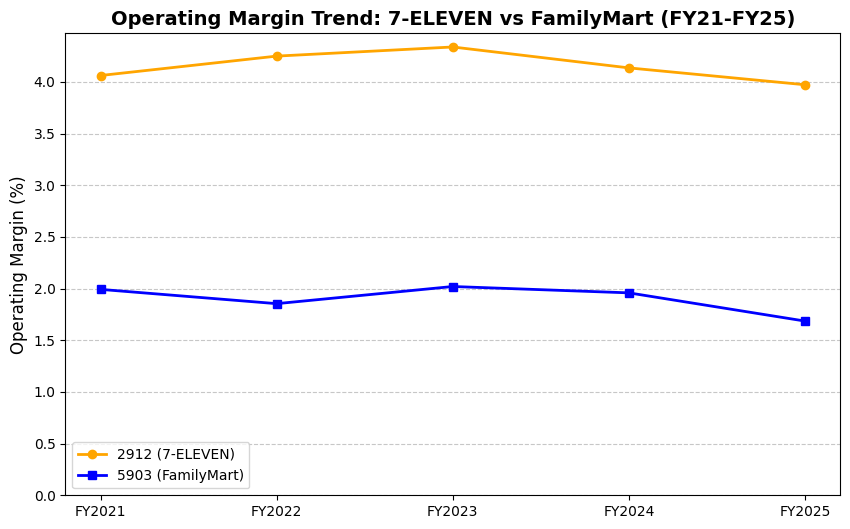

In [5]:
# ONE chart with BOTH companies on it: operating margin by year.
# Split df into one table per company first, then draw one labelled line for each of them.
# The chart needs a legend, a title, a y-label with the unit, and an honest axis: start the
# y-axis at zero, or a small difference will look like a large one.
# Draw it above this line, then:
plt.figure(figsize=(10, 6))
# 1. 將 df 拆分成兩家公司個別的表格 (Split df into one table per company first)
df2912 = df[df["company"] == 2912]
df5903 = df[df["company"] == 5903]

# 2. 畫出兩家公司的折線圖，設定 x 軸為 year，y 軸為 operating_margin，並加上標籤給圖例使用
plt.plot(df2912["year"], df2912["operating_margin"], label="2912 (7-ELEVEN)", color="orange", marker="o", linewidth=2)
plt.plot(df5903["year"], df5903["operating_margin"], label="5903 (FamilyMart)", color="blue", marker="s", linewidth=2)

# 3. 加上圖例 (legend)
plt.legend(fontsize=10)

# 4. 加上標題 (title)
plt.title("Operating Margin Trend: 7-ELEVEN vs FamilyMart (FY21-FY25)", fontsize=14, fontweight="bold")

# 5. 加上 y 軸標籤與單位 (y-label with the unit)
plt.ylabel("Operating Margin (%)", fontsize=12)

# 6. 設定 y 軸：強制從 0 開始 (start the y-axis at zero)
plt.ylim(bottom=0)

# 7. 加上水平網格線，讓數據更容易對齊閱讀
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# 2. DuPont Analysis: Drivers of ROE
ROE = net margin × asset turnover × equity multiplier. Asset turnover and the equity multiplier use
**average** balances. <br>總資產週轉率與權益乘數用**平均餘額**。

In [6]:
# One function per DuPont factor. Finish each body: one return line each.
def net_margin(net_income, revenue):
    return net_income / revenue

def asset_turnover(revenue, assets_begin, assets_end):
    return revenue / ((assets_begin + assets_end) / 2)

def equity_multiplier(assets_begin, assets_end, equity_begin, equity_end):
    return ((assets_begin + assets_end) / 2) / ((equity_begin + equity_end) / 2)

In [7]:
# Call the three functions on whole columns, then build ROE two ways.
# A function written for one number also works on a whole column: pass the columns instead.
df["nm"] = net_margin(df["net_income"], df["revenue"])                                                                               # <-- the net margin of every row, from your function
df["at"] = asset_turnover(df["revenue"], df["total_assets_begin"], df["total_assets"])                                               # <-- the asset turnover of every row, from your function
df["em"] = equity_multiplier(df["total_assets_begin"], df["total_assets"], df["total_equity_begin"], df["total_equity"])             # <-- the equity multiplier of every row, from your function
df["roe_product"] = df["nm"] * df["at"] * df["em"] * 100                                                                             # <-- the three factors multiplied together, in percent
df["roe_direct"] = (df["net_income"] / ((df["total_equity_begin"] + df["total_equity"]) / 2)) * 100                                  # <-- ROE computed directly from net income and average total equity, in percent
print(df[["company", "year", "nm", "at", "em", "roe_product", "roe_direct"]].round(2))

   company    year    nm    at    em  roe_product  roe_direct
0     2912  FY2021  0.04  1.24  4.83        22.83       22.83
1     2912  FY2022  0.04  1.30  5.06        25.03       25.03
2     2912  FY2023  0.04  1.29  5.25        27.08       27.08
3     2912  FY2024  0.04  1.28  5.28        27.52       27.52
4     2912  FY2025  0.04  1.25  5.36        25.41       25.41
5     5903  FY2021  0.02  1.30  9.23        20.16       20.16
6     5903  FY2022  0.02  1.29  9.49        25.50       25.50
7     5903  FY2023  0.02  1.34  9.04        20.49       20.49
8     5903  FY2024  0.04  1.35  7.70        39.07       39.07
9     5903  FY2025  0.02  1.37  7.26        16.18       16.18


In [8]:
# Do the two ROE columns agree on every row?
# Round both to 2 decimals FIRST, then compare with == . Why round first: Python stores decimals
# in binary, so two figures that should be identical can differ far out in the decimals.
df["roe_match"] = (df["roe_product"].round(2) == df["roe_direct"].round(2))

for m in df["roe_match"]:
    print("match:", m)       # <-- True where the two rounded values are equal
# Then write one loop that prints match: True (or False) once for every row.

match: True
match: True
match: True
match: True
match: True
match: True
match: True
match: True
match: True
match: True


In [9]:
# The five-year average ROE of each company, with groupby. Use roe_direct.
print(df.groupby("company")["roe_direct"].mean().round(2))
print(df.groupby("company")[["nm", "at", "em"]].mean().round(4))

company
2912    25.58
5903    24.28
Name: roe_direct, dtype: float64
             nm      at      em
company                        
2912     0.0390  1.2717  5.1555
5903     0.0217  1.3279  8.5459


### DuPont Analysis: Strategic Drivers of ROE

**1. Similar Output, Different Strategies**
The five-year average ROE for 7-Eleven (2912) and FamilyMart (5903) are actually very close, at around **25.58%** and **24.28%** respectively. However, their DuPont components reveal completely different business strategies.

**2. 7-ELEVEN: Driven by Core Profitability**
7-Eleven maintains a higher and more stable net margin (around **3.9%** vs FamilyMart's 2.17%). For running convenience stores, this means 7-Eleven generates shareholder returns through superior profitability and strict cost control.

**3. FamilyMart: Driven by Financial Leverage**
The equity multiplier (em) differs the most, with FamilyMart averaging around **8.55** compared to 7-Eleven's 5.16, showing a much heavier reliance on financial leverage. FamilyMart uses higher debt to boost its returns despite lower profit margins.

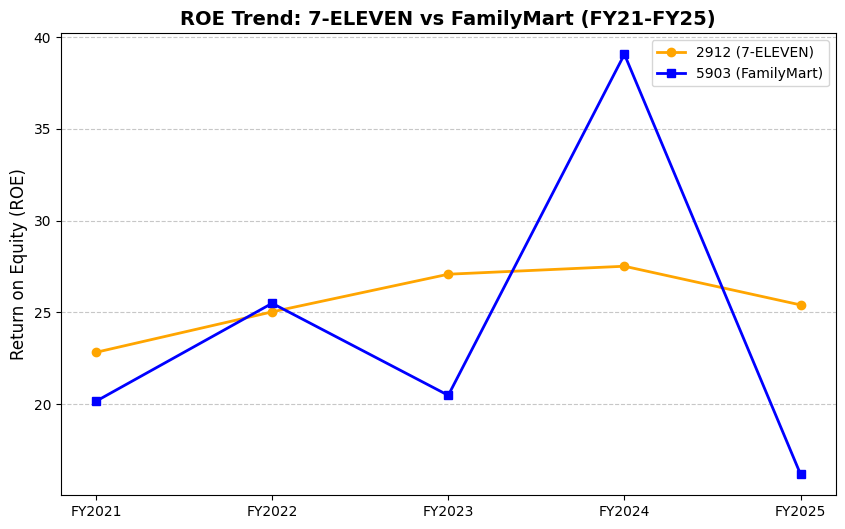

In [10]:
# 1. 建立一個寬度 10、高度 6 的專業比例畫布
plt.figure(figsize=(10, 6))

# 2. 將 df 拆分成兩家公司個別的表格 (如果前面拆過，這裡重複寫也無妨，確保可獨立執行)
df2912 = df[df["company"] == 2912]
df5903 = df[df["company"] == 5903]

# 3. 畫出兩家公司的 ROE 趨勢線 (綠色代表統一超，藍色代表全家)
plt.plot(df2912["year"], df2912["roe_direct"], label="2912 (7-ELEVEN)", color="orange", marker="o", linewidth=2)
plt.plot(df5903["year"], df5903["roe_direct"], label="5903 (FamilyMart)", color="blue", marker="s", linewidth=2)

# 4. 加上圖例、專業標題與 Y 軸標籤
plt.legend(fontsize=10)
plt.title("ROE Trend: 7-ELEVEN vs FamilyMart (FY21-FY25)", fontsize=14, fontweight="bold")
plt.ylabel("Return on Equity (ROE)", fontsize=12)

# 5. 加上水平網格線，讓數據更容易對齊閱讀
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

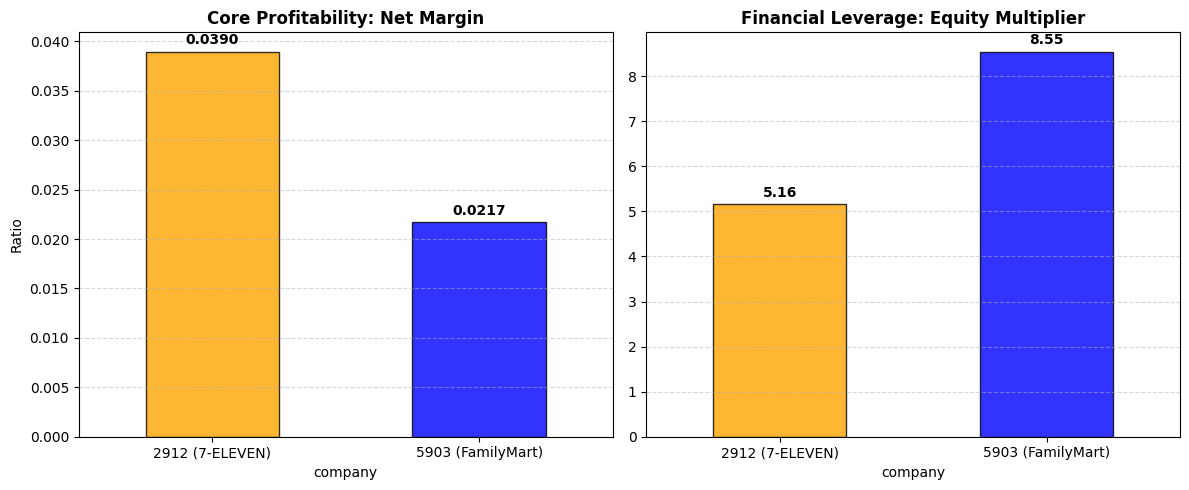

In [11]:
# 1. 先用 groupby 算出兩家公司這五年的杜邦指標平均值
dupont_avg = df.groupby("company")[["nm", "at", "em"]].mean()

# 2. 建立一個 1 列 2 欄的並排畫布，設定寬度 12、高度 5
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# 3. 左圖：本業獲利能力 (Net Margin)
# 統一超用綠色，全家用藍色
dupont_avg["nm"].plot(kind="bar", ax=axes[0], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[0].set_title("Core Profitability: Net Margin", fontsize=12, fontweight="bold")
axes[0].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[0].set_ylabel("Ratio")
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 4. 幫左圖的柱子加上數值標籤 (fmt='%.4f' 代表小數點後四位)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.4f', padding=3, fontweight="bold")

# 5. 右圖：財務槓桿 (Equity Multiplier)
dupont_avg["em"].plot(kind="bar", ax=axes[1], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[1].set_title("Financial Leverage: Equity Multiplier", fontsize=12, fontweight="bold")
axes[1].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# 6. 幫右圖的柱子加上數值標籤 (fmt='%.2f' 代表小數點後兩位)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

# 3. Stakeholder Decision Models

In [12]:
# The bank: which company is safer to lend to?

# Step 1: add the ratio columns this reader needs to df (ratio sheet in the handout).
df["interest_coverage"] = df["operating_income"] / df["finance_costs"]
df["debt_ratio"] = df["total_liabilities"] / df["total_assets"] * 100
df["current_ratio"] = df["total_current_assets"] / df["total_current_liabilities"]

# Step 2: one value of each ratio for each company. A single year or a five-year average -
#   choose what fits this reader, and say why in a comment.
#   Filter df by company AFTER adding your columns, or the new columns will be missing.
#   Five-year average: a bank lends for years, so one good or bad year should not decide.
bank_2912 = df[df["company"] == 2912]
bank_5903 = df[df["company"] == 5903]
r1_2912 = round(bank_2912["interest_coverage"].mean(), 2)
r2_2912 = round(bank_2912["debt_ratio"].mean(), 2)
r3_2912 = round(bank_2912["current_ratio"].mean(), 2)
r1_5903 = round(bank_5903["interest_coverage"].mean(), 2)
r2_5903 = round(bank_5903["debt_ratio"].mean(), 2)
r3_5903 = round(bank_5903["current_ratio"].mean(), 2)

# Step 3: the judgment. r1, r2, r3 are the three ratios; line is the threshold you will move in Step 4.
# r1 = interest coverage, r2 = debt ratio (%), r3 = current ratio
def bank_view(r1, r2, r3, line):
    if r1 < line:
        return "too risky"            # coverage is the main line: operating income must cover finance costs
    elif r2 > 60 or r3 < 0.5:

        return "lend with conditions"
    else:
        return "safe to lend"

main_line = 7     # <-- the threshold that matters most for this reader
print("【Base Scenario】    (Threshold=7) | 2912:", bank_view(r1_2912, r2_2912, r3_2912, main_line),
      "| 5903:", bank_view(r1_5903, r2_5903, r3_5903, main_line))

# Step 4: the same judgment with that threshold lower and higher.
low_line = 5
high_line = 10
print("【Lenient Scenario】 (Threshold=5) | 2912:", bank_view(r1_2912, r2_2912, r3_2912, low_line),
      "| 5903:", bank_view(r1_5903, r2_5903, r3_5903, low_line))
print("【Strict Scenario】 (Threshold=10) | 2912:", bank_view(r1_2912, r2_2912, r3_2912, high_line),
      "           | 5903:", bank_view(r1_5903, r2_5903, r3_5903, high_line))

# Step 5: print the three ratio values themselves, so every figure you quote in your written
#   answers has a cell behind it. Keep this line.
print("values | ")
print(df.groupby("company")[["interest_coverage","debt_ratio","current_ratio"]].mean().round(2))

【Base Scenario】    (Threshold=7) | 2912: lend with conditions | 5903: too risky
【Lenient Scenario】 (Threshold=5) | 2912: lend with conditions | 5903: lend with conditions
【Strict Scenario】 (Threshold=10) | 2912: too risky            | 5903: too risky
values | 
         interest_coverage  debt_ratio  current_ratio
company                                              
2912                  8.91        80.9           0.86
5903                  5.93        88.0           0.50


### Creditor Risk Assessment (Bank Perspective)

**1. Primary Verdict: 7-ELEVEN is Safer**
7-ELEVEN (2912) is the safer borrower due to a higher average interest coverage ratio of **8.91**, compared to FamilyMart's (5903) **5.93**.

**2. Liquidity & Leverage Concerns**
However, both companies carry debt ratios above 80%, and FamilyMart's weaker current ratio of **0.50** means neither is completely risk-free.

**3. Key Accounting Insight (Limitation of Debt Ratio)**
A critical limitation of this evidence is that the debt ratio merges **lease liabilities** and **trade payables** with actual bank borrowings. In the retail industry, this fails to reflect the true proportion of interest-bearing bank debt, making the 80% ratio look more alarming than the actual default risk.

### Sensitivity Analysis: Interest Coverage Ratio (Bank Perspective)

**Base Scenario (Threshold = 7)**
The primary threshold for the interest coverage ratio is set at **7**. From a creditor's perspective, operating income must cover finance costs by at least 7 times to provide an adequate margin of safety against cash flow volatility.

**Stress Testing Results:**
* **Lenient Scenario (Threshold = 5):** FamilyMart (5903) successfully passes, upgrading its rating from "too risky" to **"lend with conditions."**
* **Strict Scenario (Threshold = 10):** 7-ELEVEN (2912) is downgraded to **"too risky,"** as its coverage ratio of 8.91 fails to meet this heightened safety requirement.

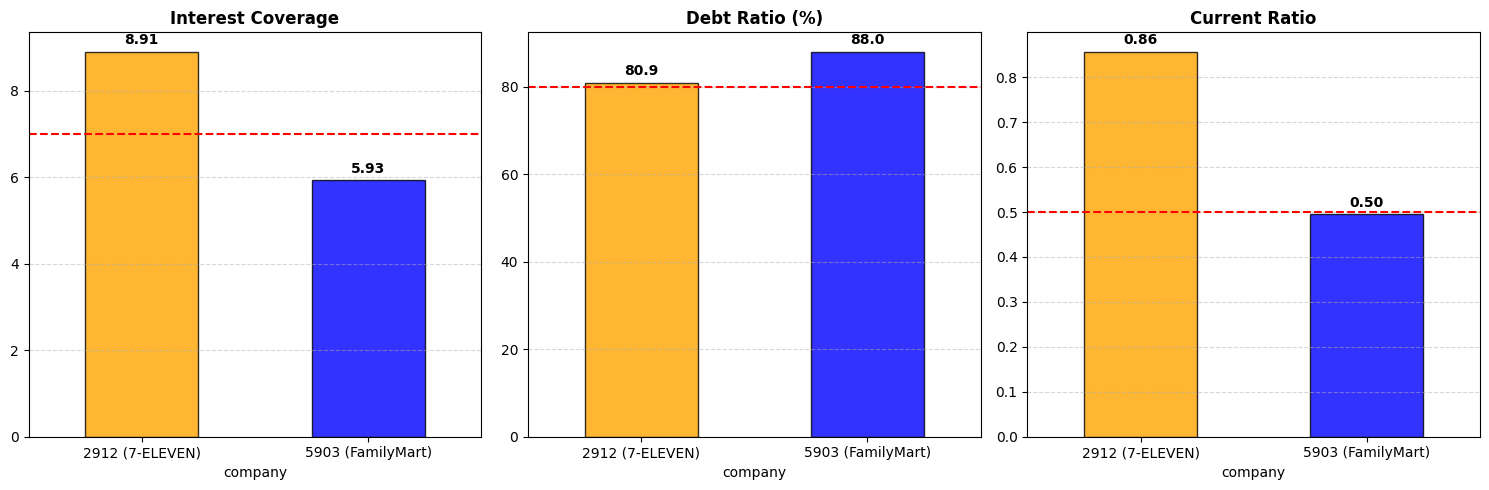

In [13]:
# 1. 抓取銀行最在意的「三個」指標：利息保障倍數、負債比率、流動比率
risk_avg = df.groupby("company")[["interest_coverage", "debt_ratio", "current_ratio"]].mean()

# 2. 建立 1 列 3 欄的並排畫布，為了塞下三張圖，把畫布寬度拉長到 15
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

# 3. 左圖 (axes[0])：利息保障倍數
risk_avg["interest_coverage"].plot(kind="bar", ax=axes[0], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[0].set_title("Interest Coverage", fontsize=12, fontweight="bold")
axes[0].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].axhline(y=7.0, color='red', linestyle='--', linewidth=1.5)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

# 4. 中圖 (axes[1])：負債比率 (Debt Ratio)
risk_avg["debt_ratio"].plot(kind="bar", ax=axes[1], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[1].set_title("Debt Ratio (%)", fontsize=12, fontweight="bold")
axes[1].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].axhline(y=80, color='red', linestyle='--', linewidth=1.5)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f', padding=3, fontweight="bold")

# 5. 右圖 (axes[2])：流動比率
risk_avg["current_ratio"].plot(kind="bar", ax=axes[2], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[2].set_title("Current Ratio", fontsize=12, fontweight="bold")
axes[2].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
axes[2].axhline(y=0.5, color='red', linestyle='--', linewidth=1.5)

for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

In [14]:
#Ｔhe long-term investor: which company would you hold for five years?
# Step 1: add the ratio columns this reader needs to df (ratio sheet in the handout).
df["ROE"] = df["net_income"] / ((df["total_equity"] + df["total_equity_begin"]) / 2)*100
df["net_margin"] = df["net_income"] / df["revenue"]*100
df["asset_turnover"] = df["revenue"] / ((df["total_assets"] + df["total_assets_begin"]) / 2)
df_2912 = df[df["company"] == 2912]
df_5903 = df[df["company"] == 5903]

# Step 2: one value of each ratio for each company. A single year or a five-year average -
#   choose what fits this reader, and say why in a comment.
#   Filter df by company AFTER adding your columns, or the new columns will be missing.

r1_2912 = df_2912["ROE"].mean()
r2_2912 = df_2912["net_margin"].mean()
r3_2912 = df_2912["asset_turnover"].mean()
r1_5903 = df_5903["ROE"].mean()
r2_5903 = df_5903["net_margin"].mean()
r3_5903 = df_5903["asset_turnover"].mean()

# Step 3: the judgment. r1, r2, r3 are the three ratios; line is the threshold you will move in Step 4.
def investor_view(r1, r2, r3, line):
    if r1 >= line and r2 >= 2.0 and r3 >= 1.2:
        return "Buy"
    elif r1 >= (line - 5) and r2 >= 1.5 and r3 >= 1.0:
        return "Hold"
    else:
        return "Avoid"

main_line = 25     # <-- the threshold that matters most for this reader
print("【Base Scenario】    (Target ROE >= 25%)  | 2912:", investor_view(r1_2912, r2_2912, r3_2912, main_line),
      " | 5903:", investor_view(r1_5903, r2_5903, r3_5903, main_line))

# Step 4: the same judgment with that threshold lower and higher.
low_line = 20
high_line = 27
print("【Lenient Scenario】 (Target ROE >= 20%)  | 2912:", investor_view(r1_2912, r2_2912, r3_2912, low_line),
      " | 5903:", investor_view(r1_5903, r2_5903, r3_5903, low_line))
print("【Strict Scenario】  (Target ROE >= 27%)  | 2912:", investor_view(r1_2912, r2_2912, r3_2912, high_line),
      "| 5903:", investor_view(r1_5903, r2_5903, r3_5903, high_line))

# Step 5: print the three ratio values themselves, so every figure you quote in your written
print("values | ")
print(df.groupby("company")[["ROE","net_margin","asset_turnover"]].mean().round(2))

【Base Scenario】    (Target ROE >= 25%)  | 2912: Buy  | 5903: Hold
【Lenient Scenario】 (Target ROE >= 20%)  | 2912: Buy  | 5903: Buy
【Strict Scenario】  (Target ROE >= 27%)  | 2912: Hold | 5903: Hold
values | 
           ROE  net_margin  asset_turnover
company                                   
2912     25.58        3.90            1.27
5903     24.28        2.17            1.33


### Long-Term Investor Assessment (Equity Perspective)

**1. Primary Verdict: 7-ELEVEN is the Preferred Choice**
Five years from now, I would choose to hold 7-ELEVEN (2912) over FamilyMart (5903) due to its superior core profitability and sustainable capital efficiency.

**2. Fundamental Drivers (ROE & Margin)**
My decision is supported by 2912's strong 5-year average Return on Equity (ROE) of 25.58%, safely underpinned by a robust net profit margin of 3.90%. In contrast, 5903 relies heavily on financial leverage to achieve a similar ROE of 24.28% with a much lower margin of 2.17%.

**3. Key Limitation (Backward-Looking Metrics)**
A key limitation of relying on these historical ratios is that backward-looking financial metrics fail to account for future macroeconomic risks, such as labor cost inflation, market saturation, or retail sector disruptions over the next five years.



### Sensitivity Analysis: ROE & Profitability (Long-Term Investor)

**Base Scenario (ROE Threshold = 25%, Net Margin >= 2.0%)**
The primary threshold is designed as a strict dual condition. In the mature retail sector, demanding a 25% ROE ensures a premium buffer above capital costs, while the 2.0% net margin acts as a realistic baseline for operational health.

**Stress Testing Results:**
*   **Lenient Scenario (ROE 20%):** Both 2912 and 5903 secure a "Buy" rating, proving their baseline strength as retail duopoly leaders.
*   **Base Scenario (ROE 25%):** 2912 maintains a "Buy", but 5903 drops to a "Hold" rating as its 24.28% ROE fails to meet the strict equity return standard.
*   **Strict Scenario (ROE 27%):** Even 2912 is downgraded to a "Hold" rating, demonstrating that at extreme hurdle rates, both companies face limitations in further equity compounding without significantly expanding their current margins.

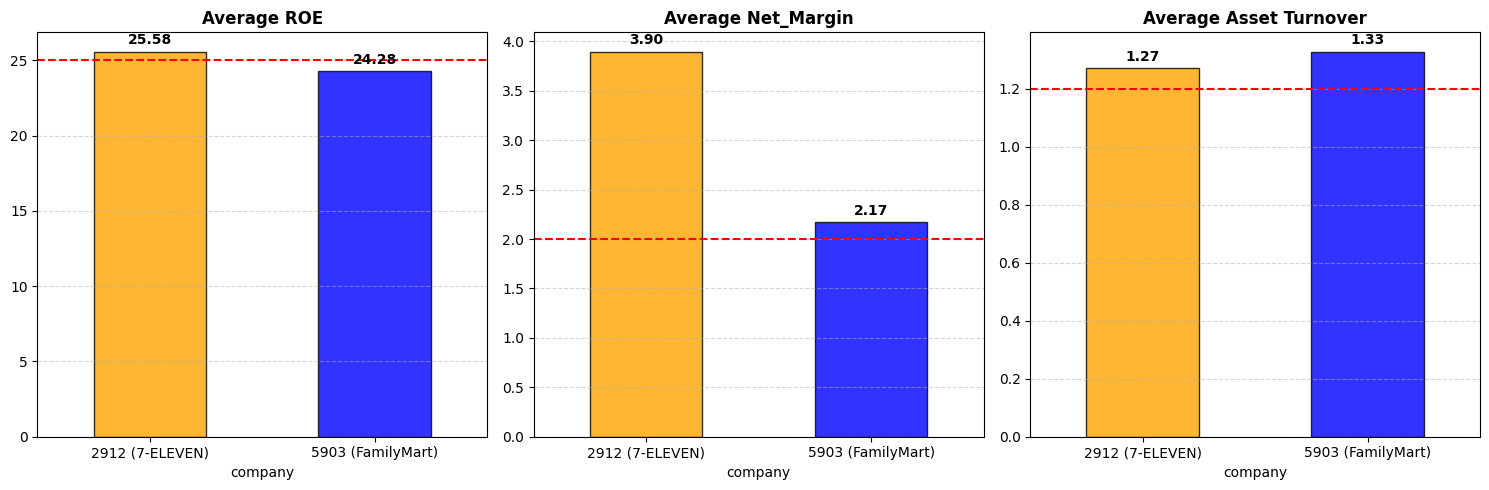

In [15]:
# 1. 抓取投資人最在意的「三個」指標：股東權益報酬率、淨利率、總資產週轉率
investor_avg = df.groupby("company")[["ROE", "net_margin", "asset_turnover"]].mean()

# 2. 建立 1 列 3 欄的並排畫布，為了塞下三張圖，把畫布寬度拉長到 15
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

# 3. 左圖 (axes[0])：股東權益報酬率
investor_avg["ROE"].plot(kind="bar", ax=axes[0], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[0].set_title("Average ROE", fontsize=12, fontweight="bold")
axes[0].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].axhline(y=25, color='red', linestyle='--', linewidth=1.5)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

# 4. 中圖 (axes[1])：淨利率
investor_avg["net_margin"].plot(kind="bar", ax=axes[1], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[1].set_title("Average Net_Margin", fontsize=12, fontweight="bold")
axes[1].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].axhline(y=2.0, color='red', linestyle='--', linewidth=1.5)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

# 5. 右圖 (axes[2])：總資產週轉率
investor_avg["asset_turnover"].plot(kind="bar", ax=axes[2], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[2].set_title("Average Asset Turnover", fontsize=12, fontweight="bold")
axes[2].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
axes[2].axhline(y=1.2, color='red', linestyle='--', linewidth=1.5)

for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

In [16]:
# The supplier: which company pays its suppliers more promptly?
# Step 1: add the ratio columns this reader needs to df (ratio sheet in the handout).
# Payables include related parties: a related-party supplier is still a supplier waiting to be paid.
df["payable_days"] = ((df["accounts_payable"] + df["accounts_payable_begin"]) / 2
                      + (df["accounts_payable_related"] + df["accounts_payable_related_begin"]) / 2) / df["cogs"] * 365
df["cash_ratio"] = df["cash"] / df["total_current_liabilities"]
df["current_ratio"] = df["total_current_assets"] / df["total_current_liabilities"]

# Step 2: one value of each ratio for each company. A single year or a five-year average -
#   choose what fits this reader, and say why in a comment.
#   Filter df by company AFTER adding your columns, or the new columns will be missing.
# Five-year average: a supplier cares about the usual payment habit, not one odd year.
sup_2912 = df[df["company"] == 2912]
sup_5903 = df[df["company"] == 5903]
r1_2912 = round(sup_2912["payable_days"].mean(), 2)
r2_2912 = round(sup_2912["cash_ratio"].mean(), 2)
r3_2912 = round(sup_2912["current_ratio"].mean(), 2)
r1_5903 = round(sup_5903["payable_days"].mean(), 2)
r2_5903 = round(sup_5903["cash_ratio"].mean(), 2)
r3_5903 = round(sup_5903["current_ratio"].mean(), 2)

# Step 3: the judgment. r1, r2, r3 are the three ratios; line is the threshold you will move in Step 4.
# r1 = payable days (lower = pays faster), r2 = cash ratio, r3 = current ratio
def supplier_view(r1, r2, r3, line):
    if r1 > line:
        return "slow payer"           # payable days above the line: the supplier waits too long
    elif r2 < 0.3 or r3 < 0.5:
        # 0.3 and 0.5 are starting guesses: stores collect cash at the till, so low ratios are normal;
        # these only flag a company with very little cash behind its promise to pay.
        return "pays on time, thin cash"
    else:
        return "prompt payer"

main_line = 60     # <-- the threshold that matters most for this reader (days)
print("【Base Scenario】   (60 days) | 2912:", supplier_view(r1_2912, r2_2912, r3_2912, main_line),
      "| 5903:", supplier_view(r1_5903, r2_5903, r3_5903, main_line))

# Step 4: the same judgment with that threshold lower and higher.
low_line = 45
high_line = 75
print("【Lenient Scenario】(75 days) | 2912:", supplier_view(r1_2912, r2_2912, r3_2912, high_line),
      "| 5903:", supplier_view(r1_5903, r2_5903, r3_5903, high_line))
print("【Strict Scenario】 (45 days) | 2912:", supplier_view(r1_2912, r2_2912, r3_2912, low_line),
      "  | 5903:", supplier_view(r1_5903, r2_5903, r3_5903, low_line))

# Step 5: print the three ratio values themselves, so every figure you quote in your written
#   answers has a cell behind it. Keep this line.
print("values | ")
print(df.groupby("company")[["payable_days","cash_ratio","current_ratio"]].mean().round(2))

【Base Scenario】   (60 days) | 2912: prompt payer | 5903: slow payer
【Lenient Scenario】(75 days) | 2912: prompt payer | 5903: pays on time, thin cash
【Strict Scenario】 (45 days) | 2912: slow payer   | 5903: slow payer
values | 
         payable_days  cash_ratio  current_ratio
company                                         
2912            53.02        0.47           0.86
5903            71.54        0.19           0.50


### Supplier Assessment (Vendor Perspective)

**1. Primary Verdict: 2912 is a More Reliable Payer**
From a supplier's perspective, 7-ELEVEN (2912) is a significantly better partner for cash conversion. Based on a standard 60-day commercial payment term (Net-60), 2912 qualifies as a "prompt payer," whereas FamilyMart (5903) is classified as a "slow payer."

**2. Fundamental Drivers (Payable Days)**
This assessment is clearly driven by the 18-day gap in their payment cycles. 2912 takes an average of 53.02 days to settle its payables—comfortably within a two-month window. In contrast, 5903 stretches its payments to an average of 71.54 days, forcing suppliers to wait much longer for cash.

**3. Key Industry Insight (Bargaining Power)**
While extended payment cycles pose liquidity risks for vendors, they are a hallmark of the convenience store business model. Giant retailers leverage their massive market dominance to squeeze suppliers, effectively using accounts payable as free, zero-interest financing to fund their own operations.



### Sensitivity Analysis: Payable Days & Liquidity (Supplier)

**Base Scenario (Payable Threshold = 60 Days, Cash Ratio < 0.3)**
The primary threshold is set at 60 days (Net-60), a widely accepted commercial standard. A dual-condition ensures that even if a company pays on time, it is flagged if its cash ratio falls below 0.3, ensuring the supplier monitors the actual liquidity backing the payment.

**Stress Testing Results:**
* **Lenient Scenario (75 Days):** When relaxing the threshold to 75 days, 2912 remains a **"prompt payer."** However, while 5903 finally manages to pay within this extended timeframe (71.54 days), it triggers the liquidity warning and is flagged as **"pays on time, thin cash"** due to its exceptionally low cash ratio of 0.19.
* **Base Scenario (60 Days):** A clear divergence emerges. 2912 successfully clears the benchmark as a **"prompt payer"**, while 5903 is downgraded to a **"slow payer"** (71.54 days).
* **Strict Scenario (45 Days):** Both companies drop to **"slow payer"**, proving that neither retail giant is willing to sacrifice its free working capital to settle accounts within a tight 45-day window.

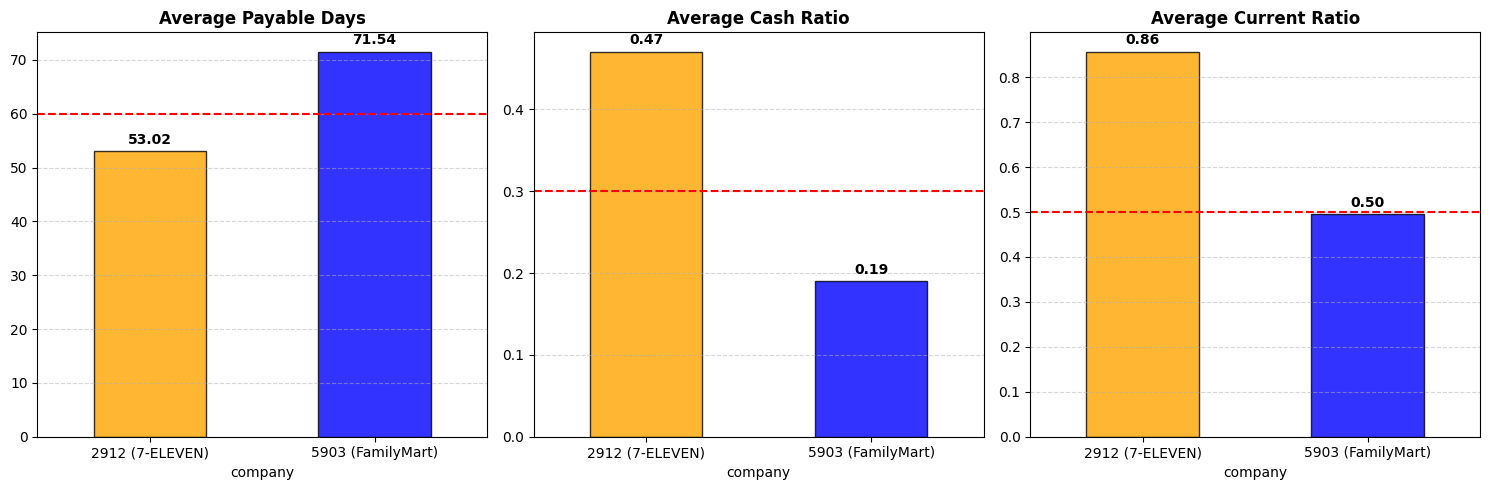

In [17]:
# 1. 抓取供應商最在意的「三個」指標：應付帳款天數、現金比率、流動比率
supplier_avg = df.groupby("company")[["payable_days", "cash_ratio", "current_ratio"]].mean()

# 2. 建立 1 列 3 欄的並排畫布，為了塞下三張圖，把畫布寬度拉長到 15
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

# 3. 左圖 (axes[0])：應付帳款天數
supplier_avg["payable_days"].plot(kind="bar", ax=axes[0], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[0].set_title("Average Payable Days", fontsize=12, fontweight="bold")
axes[0].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].axhline(y=60, color='red', linestyle='--', linewidth=1.5)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

# 4. 中圖 (axes[1])：現金比率
supplier_avg["cash_ratio"].plot(kind="bar", ax=axes[1], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[1].set_title("Average Cash Ratio", fontsize=12, fontweight="bold")
axes[1].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].axhline(y=0.3, color='red', linestyle='--', linewidth=1.5)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

# 5. 右圖 (axes[2])：流動比率
supplier_avg["current_ratio"].plot(kind="bar", ax=axes[2], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[2].set_title("Average Current Ratio", fontsize=12, fontweight="bold")
axes[2].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
axes[2].axhline(y=0.5, color='red', linestyle='--', linewidth=1.5)

for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

In [18]:
# The manager: which company earns more from the assets it uses?
# Step 1: add the ratio columns this reader needs to df (ratio sheet in the handout).
df["ROA"] = df["net_income"] / ((df["total_assets"] + df["total_assets_begin"]) / 2)*100
df["asset_turnover"] = df["revenue"] / ((df["total_assets"] + df["total_assets_begin"]) / 2)
df["operating_margin"] = df["operating_income"] / df["revenue"]*100

df_2912 = df[df["company"] == 2912]
df_5903 = df[df["company"] == 5903]
# Step 2: one value of each ratio for each company. A single year or a five-year average -
#   choose what fits this reader, and say why in a comment.
#   Filter df by company AFTER adding your columns, or the new columns will be missing.
r1_2912 = df_2912["ROA"].mean()
r2_2912 = df_2912["asset_turnover"].mean()
r3_2912 = df_2912["operating_margin"].mean()
r1_5903 = df_5903["ROA"].mean()
r2_5903 = df_5903["asset_turnover"].mean()
r3_5903 = df_5903["operating_margin"].mean()

# Step 3: the judgment. r1, r2, r3 are the three ratios; line is the threshold you will move in Step 4.
def manager_view(r1, r2, r3, line):
    if r1 >= line and r2 >= 1.2 and r3 >= 3:
        return "Efficient"
    elif r1 >= (line - 2) and r2 >= 1.0 and r3 >= 1.5:
        return "Moderate"
    else:
        return "Inefficient"

main_line = 6     # <-- the threshold that matters most for this reader
print("【Base Scenario】   (Threshold = 6%) | 2912:", manager_view(r1_2912, r2_2912, r3_2912, main_line),
      "   | 5903:", manager_view(r1_5903, r2_5903, r3_5903, main_line))

# Step 4: the same judgment with that threshold lower and higher.
low_line = 4
high_line = 8
print("【Lenient Scenario】(Threshold = 4%) | 2912:", manager_view(r1_2912, r2_2912, r3_2912, low_line),
      "  | 5903:", manager_view(r1_5903, r2_5903, r3_5903, low_line))
print("【Strict Scenario】 (Threshold = 8%) | 2912:", manager_view(r1_2912, r2_2912, r3_2912, high_line),
      "| 5903:", manager_view(r1_5903, r2_5903, r3_5903, high_line))

# Step 5: print the three ratio values themselves, so every figure you quote in your written
print("values | ")
print(df.groupby("company")[["ROA","asset_turnover","operating_margin"]].mean().round(2))

【Base Scenario】   (Threshold = 6%) | 2912: Moderate    | 5903: Inefficient
【Lenient Scenario】(Threshold = 4%) | 2912: Efficient   | 5903: Moderate
【Strict Scenario】 (Threshold = 8%) | 2912: Inefficient | 5903: Inefficient
values | 
          ROA  asset_turnover  operating_margin
company                                        
2912     4.96            1.27              4.15
5903     2.89            1.33              1.90


### Managerial Assessment (Operating Efficiency Perspective)

**1. Primary Verdict: 2912 Outperforms 5903 in Asset Productivity**
From an operational management perspective, Company 2912 (President Chain Store) generates profit from its asset base more efficiently than Company 5903 (FamilyMart). Based on a strict primary Return on Assets (ROA) threshold of 6%, 2912 maintains a "Moderate" standing, whereas 5903 struggles at "Inefficient."

**2. Fundamental Drivers (ROA & Operating Margin)**
This performance gap is driven by 2912's superior cost control. 2912 delivers a 5-year average ROA of 4.96% supported by a robust operating margin of 4.15%. In contrast, while 5903 has a slightly faster asset turnover (1.33 vs. 2912's 1.27), its thin operating margin of 1.90% severely drags down its overall ROA to just 2.89%.

**3. Key Accounting Limitation (Historical Cost Distortion)**
A key accounting limitation of asset-based efficiency metrics is that property and equipment are recorded at historical cost minus accumulated depreciation. For mature retail chains with older, fully depreciated store assets, this can artificially depress asset bases and inflate productivity ratios compared to newer networks.

### Sensitivity Analysis: Operating Efficiency Threshold (Manager)

**Base Scenario (ROA Threshold = 6%)**
The main threshold is set at a strict ROA of 6%. In convenience-store accounting, this level ensures that retail asset productivity comfortably covers heavy store depreciation costs while exceeding the firm's cost of capital.

**Stress Testing Results (Step 4 Output):**
*   **Lenient Scenario (ROA 4%):** 2912 achieves an "Efficient" rating, while 5903 successfully holds at "Moderate", showing it can survive under a lowered efficiency bar.
*   **Base Scenario (ROA 6%):** 2912 is downgraded to "Moderate" and 5903 falls entirely to "Inefficient" due to its inability to generate sufficient returns (2.89% ROA) from its asset base.
*   **Strict Scenario (ROA 8%):** Both companies shift to "Inefficient", demonstrating that extreme efficiency benchmarks are difficult to meet even for retail leaders without significantly expanding their core margins.

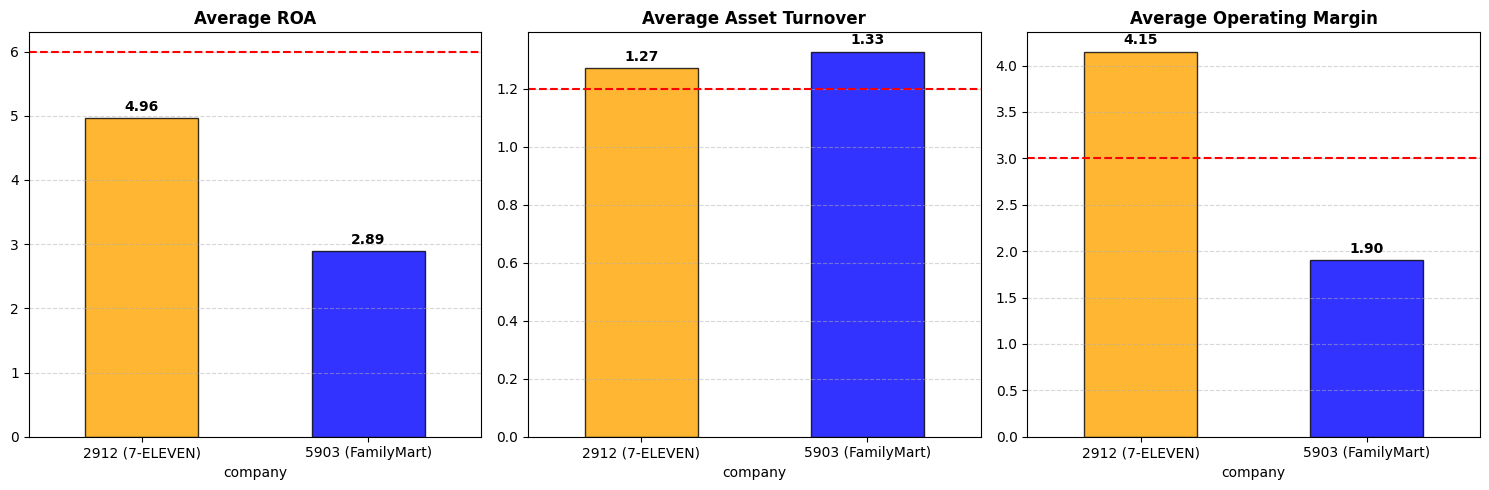

In [19]:
# 1. 抓取經理人最在意的「三個」指標：資產報酬率、總資產週轉率、營業利益率
manger_avg = df.groupby("company")[["ROA", "asset_turnover", "operating_margin"]].mean()

# 2. 建立 1 列 3 欄的並排畫布，為了塞下三張圖，把畫布寬度拉長到 15
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

# 3. 左圖 (axes[0])：資產報酬率
manger_avg["ROA"].plot(kind="bar", ax=axes[0], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[0].set_title("Average ROA", fontsize=12, fontweight="bold")
axes[0].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].axhline(y=6, color='red', linestyle='--', linewidth=1.5)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

# 4. 中圖 (axes[1])：總資產週轉率
manger_avg["asset_turnover"].plot(kind="bar", ax=axes[1], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[1].set_title("Average Asset Turnover", fontsize=12, fontweight="bold")
axes[1].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].axhline(y=1.2, color='red', linestyle='--', linewidth=1.5)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

# 5. 右圖 (axes[2])：營業利益率
manger_avg["operating_margin"].plot(kind="bar", ax=axes[2], color=["orange", "blue"], alpha=0.8, edgecolor="black")
axes[2].set_title("Average Operating Margin", fontsize=12, fontweight="bold")
axes[2].set_xticklabels(["2912 (7-ELEVEN)", "5903 (FamilyMart)"], rotation=0)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
axes[2].axhline(y=3, color='red', linestyle='--', linewidth=1.5)

for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.2f', padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

### Do the four readers agree?
 Yes, all four stakeholders favor 7-ELEVEN (2912) based on the financial figures, but the margin of victory varies significantly depending on their perspective. The bank and the supplier see a wide gap, as 2912 demonstrates superior interest coverage (8.91 vs. 5.93) and much faster payable days (53.02 vs. 71.54). For the manager, neither company reaches the strict 6% ROA "Efficient" benchmark, but 2912's 4.96% ("Moderate") clearly beats 5903's 2.89% ("Inefficient"). However, the long-term investor sees a much narrower gap, with 2912 achieving a "Buy" rating (ROE 25.58%) and 5903 close behind with a "Hold" (ROE 24.28%). They differ because the bank and supplier focus on short-term liquidity, while the investor looks at overall equity returns, where 5903's higher financial leverage (debt ratio) artificially boosts its ROE closer to 2912's level despite having weaker operational profitability.